# EDA 
W tym notatniku przyjrzymy się bliżej `full_df.csv`, zlokalizujemy potencjalne problemy z danymi i przeprowadzimy wstępne analizy

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

c:\Users\48666\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:22: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.4' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
c:\Users\48666\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


Zacznijmy od przyjrzenia się strukturze df - typom kolumn rozmiarowi

In [3]:
df = pd.read_csv('full_df.csv')

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6392 entries, 0 to 6391
Data columns (total 19 columns):
 #   Column                     Non-Null Count  Dtype
---  ------                     --------------  -----
 0   ID                         6392 non-null   int64
 1   Patient Age                6392 non-null   int64
 2   Patient Sex                6392 non-null   str  
 3   Left-Fundus                6392 non-null   str  
 4   Right-Fundus               6392 non-null   str  
 5   Left-Diagnostic Keywords   6392 non-null   str  
 6   Right-Diagnostic Keywords  6392 non-null   str  
 7   N                          6392 non-null   int64
 8   D                          6392 non-null   int64
 9   G                          6392 non-null   int64
 10  C                          6392 non-null   int64
 11  A                          6392 non-null   int64
 12  H                          6392 non-null   int64
 13  M                          6392 non-null   int64
 14  O                          6392 non

In [8]:
df.head(5).T

,0,1,2,3,4
ID,0,1,2,4,5
Patient Age,69,57,42,53,50
Patient Sex,Female,Male,Male,Male,Female
Left-Fundus,0_left.jpg,1_left.jpg,2_left.jpg,4_left.jpg,5_left.jpg
Right-Fundus,0_right.jpg,1_right.jpg,2_right.jpg,4_right.jpg,5_right.jpg
Left-Diagnostic Keywords,cataract,normal fundus,laser spot，moderate non proliferative retinopathy,macular epiretinal membrane,moderate non proliferative retinopathy
Right-Diagnostic Keywords,normal fundus,normal fundus,moderate non proliferative retinopathy,mild nonproliferative retinopathy,moderate non proliferative retinopathy
N,0,1,0,0,0
D,0,0,1,1,1
G,0,0,0,0,0


In [11]:
df.isna().sum(axis = 0)

ID                           0
Patient Age                  0
Patient Sex                  0
Left-Fundus                  0
Right-Fundus                 0
Left-Diagnostic Keywords     0
Right-Diagnostic Keywords    0
N                            0
D                            0
G                            0
C                            0
A                            0
H                            0
M                            0
O                            0
filepath                     0
labels                       0
target                       0
filename                     0
dtype: int64

Nie ma żadnych `NaN` w zbiorze danych

In [16]:
print(f"Wymiar ramki danych: {df.shape}")

Wymiar ramki danych: (6392, 19)


In [14]:
df.describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
ID,6392.0,2271.15,1417.56,0.0,920.75,2419.5,3294.0,4784.0
Patient Age,6392.0,57.86,11.73,1.0,51.00,59.0,66.0,91.0
N,6392.0,0.33,0.47,0.0,0.00,0.0,1.0,1.0
D,6392.0,0.33,0.47,0.0,0.00,0.0,1.0,1.0
G,6392.0,0.06,0.24,0.0,0.00,0.0,0.0,1.0
C,6392.0,0.06,0.24,0.0,0.00,0.0,0.0,1.0
A,6392.0,0.05,0.22,0.0,0.00,0.0,0.0,1.0
H,6392.0,0.03,0.18,0.0,0.00,0.0,0.0,1.0
M,6392.0,0.05,0.21,0.0,0.00,0.0,0.0,1.0
O,6392.0,0.25,0.43,0.0,0.00,0.0,0.0,1.0


Widać zatem, że:
- `ID` – unikalny identyfikator pacjenta (`int64`); jeden pacjent może mieć 1 lub 2 rekordy w tabeli.
- `Patient Age` – wiek pacjenta w latach (`int64`, zakres 1–91 lat, średnia ~58 lat; wymaga oczyszczenia anomalii wieku 1).
- `Patient Sex` – płeć pacjenta (`str`: 'Male' / 'Female').
- `Left-Fundus` – nazwa pliku bazowego ze zdjęciem dna lewego oka (`str`, np. `0_left.jpg`).
- `Right-Fundus` – nazwa pliku bazowego ze zdjęciem dna prawego oka (`str`, np. `0_right.jpg`).
- `Left-Diagnostic Keywords` – słowny opis diagnostyczny lekarza dla lewego oka (`str`).
- `Right-Diagnostic Keywords` – słowny opis diagnostyczny lekarza dla prawego oka (`str`).
- `N, D, G, C, A, H, M, O` – 8 flag binarnych (`int64`: 0 lub 1) sumarycznej diagnozy pacjenta:
  - `N` (*Normal*) – stan prawidłowy / zdrowe oko
  - `D` (*Diabetes*) – retinopatia cukrzycowa
  - `G` (*Glaucoma*) – jaskra
  - `C` (*Cataract*) – zaćma
  - `A` (*AMD*) – zwyrodnienie plamki żółtej
  - `H` (*Hypertension*) – retinopatia nadciśnieniowa
  - `M` (*Myopia*) – krótkowzroczność patologiczna
  - `O` (*Others*) – inne schorzenia
- `filepath` – archiwalna ścieżka do pliku obrazu w środowisku Kaggle (`str`).
- `labels` – właściwa klasa diagnostyczna przypisana do konkretnego zdjęcia w danym wierszu (`str`, np. `['N']`, `['C']`).
- `target` – reprezentacja One-Hot Encoding etykiety `labels` w postaci wektora 8-elementowego (`str`).
- `filename` – nazwa pliku obrazu z folderu `preprocessed_images`, do którego odnosi się dany wiersz (`str`, np. `0_right.jpg`).



In [36]:
# Sprawdzimy ile pacjentow ma 2 rekordy w bazie, a ile tylko 1
df_wynik = df.groupby("ID")["ID"].count().reset_index(name="Liczba wystąpień")
df_koncowy = df_wynik.groupby("Liczba wystąpień").size().reset_index(name="Ile takich ID")
print(df_koncowy)

   Liczba wystąpień  Ile takich ID
0                 1            324
1                 2           3034


N    33.0
D    33.0
G     6.0
C     6.0
A     5.0
H     3.0
M     5.0
O    25.0
dtype: float64

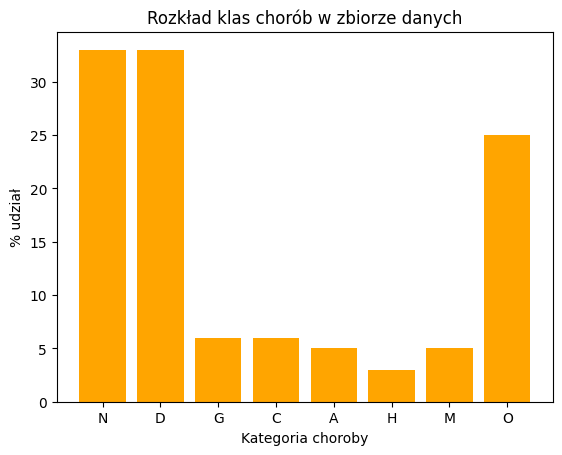

In [57]:
# Zbadamy rozkład klas chorób
cols = ['N', 'D', 'G','C', 'A', 'H', 'M', 'O']
distribution = df[cols].mean().round(2) * 100
display(distribution)

plt.bar(cols, distribution, color = 'orange')
plt.title("Rozkład klas chorób w zbiorze danych")
plt.xlabel("Kategoria choroby")
plt.ylabel("% udział")
plt.show()

---

### Krótka charakterystyka zbioru:
1. **Wymiary i kompletność:** 6392 wiersze i 19 kolumn; zbiór nie zawiera żadnych brakujących wartości (`NaN`).
2. **Jednostka obserwacji:** 1 wiersz reprezentuje pojedyncze oko (3194 prawych i 3198 lewych). Dane pochodzą od 3358 unikalnych pacjentów (3034 pacjentów posiada komplet obu oczu, a 324 tylko jedno oko).
3. **Niezbalansowanie klas:** Klasy są silnie niezbalansowane — dominują oczy zdrowe `N` oraz zmiany cukrzycowe `D` (ok 33%), podczas gdy pozostałe patologie stanowią po ok 5% zbioru. Wyjątek stanowi kategoria `O` która stanowi ok 25% zbiori
4. **Wymóg walidacji:** Ze względu na występowanie obu oczu tego samego pacjenta, podział na zbiór treningowy i testowy musi uwzględniać grupowanie po kolumnie `ID` (`StratifiedGroupKFold`), aby uniknąć *data leakage*.

Mamy 2 podejrzenia dotyczące zbioru danych: 
- Czy wiek `1` to rzeczywiscie wiek rocznego pacjenta, czy może sposob na uniknięcie `NaN`
- Czy pod kategorią `O` kryje się coś ciekawego

In [ ]:
df_other = df.loc[df["labels"] == "['O']", :]
df_other.groupby(["Left-Diagnostic Keywords", "Right-Diagnostic Keywords"]).size().sort_values(ascending=False)
#policzyc udzial po prostu lacznie oka prawego i lewego co tam jest i ile z tego jest rzeczywiscei wartosciowe

Left-Diagnostic Keywords                                            Right-Diagnostic Keywords            
drusen                                                              drusen                                   76
normal fundus                                                       macular epiretinal membrane              48
macular epiretinal membrane                                         normal fundus                            33
normal fundus                                                       epiretinal membrane                      30
epiretinal membrane                                                 normal fundus                            24
                                                                                                             ..
epiretinal membrane，epiretinal membrane，lens dust                   lens dust，macular epiretinal membrane     1
macular epiretinal membrane，severe nonproliferative retinopathy     normal fundus                             